# 04. Evaluation & Optimization — ROKEY
**목표:** 03번 추천 엔진과 동일한 점수/정렬로 실제 마지막 주문의 숨긴 상품군을 예측한다. Prior로 계산한 v3 통계는 고정하고 공개 train 주문을 고객 단위 validation/test로 나눈다. 신규 고객은 R을 숨기는 모의 실험이다. 27개 대리 상품군 평가이며 실제 한국 편의점 구매 성과가 아니다.

실행: Colab CPU, 위에서부터 실행. 기존 Drive 경로 유지. 66개 가중치 탐색은 validation만 사용. 최종 test 결과로 재튜닝하지 않는다.

In [1]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/2026_02_ROKEY/07_cobot2')
DATA=ROOT/'instacart'; BASE=ROOT/'recommender'; VERSION='pattern_analysis_v3'; SRC=BASE/VERSION
OUT=BASE/'evaluation_v3'; OUT.mkdir(parents=True,exist_ok=True)
SEED=42
# None = 전체 평가. 빠른 점검 시 2000 등으로 변경 (최종 결과와 구분)
MAX_CASES=None


Mounted at /content/drive


## 1. 03번 엔진 그대로 로드
첨부한 실행 완료 노트북에서 입력, 점수 계산 및 추천 함수를 복사했다. 최소 200건, S=1~5 코너, C=2~5 코너, Lift 비중 0.5 고정.

In [2]:
meta=json.loads((SRC/'pattern_metadata.json').read_text())
ids=meta['item_ids']; idx={x:i for i,x in enumerate(ids)}
aisle=meta['item_aisle']; names=pd.read_csv(SRC/'mapping_coverage.csv').set_index('id')['name'].to_dict()
R=sparse.load_npz(SRC/'repurchase_R.npz').tocsr()
users=np.load(SRC/'user_ids.npy',allow_pickle=False)
user_index={int(u):i for i,u in enumerate(users)}
S=pd.read_csv(SRC/'same_aisle_scores.csv'); C=pd.read_csv(SRC/'cross_aisle_scores.csv')
assert R.shape==(len(users),len(ids)) and len(user_index)==len(users)
assert set(ids)==set(aisle)==set(names)
assert np.isfinite(R.data).all() and ((R.data>=0)&(R.data<=1)).all()
print('R shape:',R.shape,'S pairs:',len(S),'C pairs:',len(C))


R shape: (206209, 27) S pairs: 30 C pairs: 1386


In [3]:
MIN_COUNT=200
S_SCOPE='aisles_1_5'; C_SCOPE='aisles_2_5'
LIFT_WEIGHT=.5
WEIGHTS=(.4,.3,.3)
def pair_scores(df,scope):
    t=df[df.scope.eq(scope)].copy()
    assert not t.duplicated(['source','target']).any()
    t['valid']=t.observed & t['count'].ge(MIN_COUNT)
    t['lift_scaled']=1-1/t.lift.clip(lower=1)
    t['score']=(1-LIFT_WEIGHT)*t.confidence+LIFT_WEIGHT*t.lift_scaled
    return {(r.source,r.target):float(r.score) for r in t.itertuples() if r.valid}
s_pairs=pair_scores(S,S_SCOPE); c_pairs=pair_scores(C,C_SCOPE)
# 상품군별 인기도: R * 고객별 주문 수를 합산 / 전체 주문 수
counts=np.load(SRC/'user_order_counts.npy',allow_pickle=False)
assert len(counts)==len(users) and counts.sum()>0
pop=np.asarray(R.T @ counts).ravel()/counts.sum()
print('유효 S:',len(s_pairs),'유효 C:',len(c_pairs))
print('인기순:',[(names[ids[i]],round(float(pop[i]),3)) for i in np.argsort(-pop)[:5]])


유효 S: 8 유효 C: 434
인기순: [('소형 우유팩', 0.244), ('요구르트', 0.244), ('생수', 0.191), ('식빵', 0.164), ('계란 모형', 0.137)]


In [4]:
def recommend(basket=(), user_id=None, stock=None, weights=WEIGHTS, k=3, history_scores=None):
    basket=list(dict.fromkeys(basket))
    if any(x not in idx for x in basket): raise ValueError('미등록 상품 ID: '+str(set(basket)-set(ids)))
    w=np.asarray(weights,dtype=float)
    if w.shape!=(3,) or not np.isfinite(w).all() or (w<0).any() or w.sum()==0: raise ValueError('잘못된 가중치')
    if history_scores is not None:
        r=np.array([history_scores.get(x,0) for x in ids],dtype=float)
        if not np.isfinite(r).all() or ((r<0)|(r>1)).any(): raise ValueError('R은 0~1')
        has_r=bool(history_scores)
    else:
        has_r=user_id in user_index
        r=R.getrow(user_index[user_id]).toarray().ravel() if has_r else np.zeros(len(ids))
    rows=[]
    for j in ids:
        if j in basket or (stock is not None and stock.get(j,0)<=0): continue
        sv=[s_pairs[(i,j)] for i in basket if aisle[i]==aisle[j] and (i,j) in s_pairs]
        cv=[c_pairs[(aisle[i],aisle[j])] for i in basket if aisle[i]!=aisle[j] and (aisle[i],aisle[j]) in c_pairs]
        rows.append(dict(id=j,name=names[j],R=float(r[idx[j]]),S=sum(sv)/max(1,len(basket)),C=sum(cv)/max(1,len(basket)),S_evidence=len(sv),C_evidence=len(cv),popularity=float(pop[idx[j]])))
    columns=['id','name','R','S','C','S_evidence','C_evidence','popularity','score','reason']
    if not rows: return pd.DataFrame(columns=columns)
    t=pd.DataFrame(rows)
    active=np.array([has_r,t.S_evidence.gt(0).any(),t.C_evidence.gt(0).any()])
    effective=w*active
    if effective.sum()>0:
        effective/=effective.sum(); t['score']=t[['R','S','C']].to_numpy()@effective
        t['reason']=np.where(t.score.gt(0),'hybrid','popularity_fallback')
    else:
        t['score']=t.popularity; t['reason']='popularity_fallback'
    t=t.sort_values(['score','popularity','id'],ascending=[False,False,True]).head(k).reset_index(drop=True)
    t.attrs['effective_weights']=effective.tolist()
    return t


## 2. 평가 데이터 생성
동일 product_mapping.csv를 사용한다. 마지막 주문에서 매핑된 서로 다른 상품군이 2개 이상인 경우 한 상품군을 무작위로 숨긴다. 매핑되지 않은 상품은 평가 후보에 포함하지 않는다. 전체 주문 중 평가 가능 비율을 기록한다.

In [5]:
mapping=pd.read_csv(SRC/'product_mapping.csv',usecols=['product_id','id'])
assert mapping.product_id.is_unique and mapping.id.isin(ids).all()
orders=pd.read_csv(DATA/'orders.csv',usecols=['order_id','user_id','eval_set'])
last=orders.loc[orders.eval_set.eq('train'),['order_id','user_id']].copy()
assert last.user_id.is_unique and last.order_id.is_unique
train=pd.read_csv(DATA/'order_products__train.csv',usecols=['order_id','product_id'])
assert train.order_id.isin(last.order_id).all()
mapped=train.merge(mapping,on='product_id',validate='many_to_one').drop_duplicates(['order_id','id'])
groups=mapped.groupby('order_id').id.agg(lambda x: sorted(x))
eligible=last.merge(groups.rename('items'),left_on='order_id',right_index=True)
eligible=eligible[eligible['items'].map(len)>=2].sort_values('user_id').reset_index(drop=True)
assert eligible.user_id.isin(users).all()
coverage={'all_train_orders':len(last),'mapped_orders':int(groups.size),'eligible_orders':len(eligible),'eligible_fraction':len(eligible)/len(last),'mapped_raw_line_fraction':float(train.product_id.isin(mapping.product_id).mean())}
print(coverage)
rng=np.random.default_rng(SEED)
eligible['target']=[x[rng.integers(len(x))] for x in eligible['items']]
eligible['basket']=[[i for i in x if i!=t] for x,t in zip(eligible['items'],eligible.target)]
eligible=eligible.iloc[rng.permutation(len(eligible))].reset_index(drop=True)
if MAX_CASES is not None: eligible=eligible.head(MAX_CASES).copy()
assert len(eligible)>=4
mid=len(eligible)//2
val=eligible.iloc[:mid].copy(); test=eligible.iloc[mid:].copy()
assert not set(val.user_id)&set(test.user_id)
print('validation/test:',len(val),len(test))


{'all_train_orders': 131209, 'mapped_orders': 109070, 'eligible_orders': 76781, 'eligible_fraction': 0.5851808946032665, 'mapped_raw_line_fraction': 0.2729570704389734}
validation/test: 38390 38391


## 3. 빠른 평가 엔진
03번과 동일하게 장바구니 전체 길이로 S/C 점수를 나누고, 요청 단위로 유효 채널을 선택한다. 후보별 0점과 근거 부족을 구분한다. 재고는 모두 있다고 가정하며 이미 담은 상품은 제외한다. 기존 Lift 비교는 같은 27개 후보와 C 통계로 재구성한 **Lift-only proxy**(최대 Lift, strong/weak, 인기순 보충)이다. 기존 웹의 JSON 후보 제한 및 코너 중복 제거까지 동일한 재현은 아니다.

In [6]:
m=len(ids); id_order=np.argsort(np.array(ids)); tie_order=id_order[np.argsort(-pop[id_order],kind='stable')]
sm=np.zeros((m,m)); cm=sm.copy(); se=sm.copy(); ce=sm.copy(); lm=sm.copy()
for i,a in enumerate(ids):
    for j,b in enumerate(ids):
        if a==b: continue
        if aisle[a]==aisle[b] and (a,b) in s_pairs: sm[i,j]=s_pairs[a,b]; se[i,j]=1
        if aisle[a]!=aisle[b] and (aisle[a],aisle[b]) in c_pairs: cm[i,j]=c_pairs[aisle[a],aisle[b]]; ce[i,j]=1
lift_lookup={(r.source,r.target):r.lift for r in C[C.scope.eq(C_SCOPE)&C.observed&C['count'].ge(MIN_COUNT)].itertuples()}
for i,a in enumerate(ids):
    for j,b in enumerate(ids):
        l=lift_lookup.get((aisle[a],aisle[b]),0)
        if aisle[a]!=aisle[b] and l>=1.1: lm[i,j]=(200 if l>=1.2 else 100)+l

def prepare(frame):
    b=np.zeros((len(frame),m),bool)
    for i,items in enumerate(frame.basket): b[i,[idx[x] for x in items]]=True
    den=b.sum(1)[:,None]
    r=R[[user_index[int(u)] for u in frame.user_id]].toarray()
    s=(b@sm)/den; c=(b@cm)/den
    active=np.column_stack([np.ones(len(b),bool),((b@se>0)&~b).any(1),((b@ce>0)&~b).any(1)])
    lift=np.broadcast_to(pop,(len(b),m)).copy()
    for i in range(m): lift=np.maximum(lift,np.where(b[:,i,None],lm[i],0))
    target=np.array([idx[x] for x in frame.target])
    return dict(b=b,r=r,s=s,c=c,active=active,lift=lift,target=target,repeat=r[np.arange(len(b)),target]>0)

def scores(d,w,cold=False):
    a=d['active'].copy()
    if cold: a[:,0]=False
    e=a*np.asarray(w); den=e.sum(1)
    e=np.divide(e,den[:,None],out=np.zeros_like(e,dtype=float),where=den[:,None]>0)
    sc=d['r']*e[:,0,None]+d['s']*e[:,1,None]+d['c']*e[:,2,None]
    sc[den==0]=pop
    return sc

def top3(d,sc):
    sc=np.where(d['b'],-np.inf,sc)
    ranked=tie_order[np.argsort(-sc[:,tie_order],axis=1,kind='stable')[:,:3]]
    return np.where(np.take_along_axis(d['b'],ranked,axis=1),-1,ranked)

def metrics(d,pred,mask=None):
    if mask is None: mask=np.ones(len(pred),bool)
    pred=pred[mask]; target=d['target'][mask]
    if not len(pred): return dict(n=0,Hit1=np.nan,Hit3=np.nan,MRR3=np.nan,Coverage=np.nan)
    match=pred==target[:,None]
    return dict(n=len(pred),Hit1=match[:,0].mean(),Hit3=match.any(1).mean(),MRR3=(match/np.arange(1,4)).sum(1).mean(),Coverage=np.unique(pred[pred>=0]).size/m)
V=prepare(val)
# 03번 함수와 벡터화 코드 일치 검사 (동률 부동소수점 차이는 점수 허용오차로 확인)
check_scores=scores(V,WEIGHTS)
for i,row in enumerate(val.head(30).itertuples()):
    ref=recommend(row.basket,int(row.user_id),weights=WEIGHTS,k=3)
    sc=check_scores[i]
    got=top3({'b':V['b'][i:i+1]},sc[None,:])[0]
    assert np.allclose(sc[got[got>=0]],ref.score.to_numpy(),atol=1e-10), (row.user_id,got,ref.id.tolist())
print('03 점수 일치 확인')


03 점수 일치 확인


## 4. Validation: 66개 가중치 탐색
Hit@3 최대, 동률이면 MRR@3, Hit@1 순서로 선택한다. 나머지 동률은 고정된 가중치 순서. 신규 고객은 별도 최적화하지 않고 같은 최적 가중치에서 R을 비활성화한다.

In [7]:
grid=[(a/10,b/10,(10-a-b)/10) for a in range(11) for b in range(11-a)]
search=[]
for w in grid:
    pred=top3(V,scores(V,w)); search.append(dict(R=w[0],S=w[1],C=w[2],**metrics(V,pred)))
search=pd.DataFrame(search).sort_values(['Hit3','MRR3','Hit1','R','S','C'],ascending=[False,False,False,False,False,False]).reset_index(drop=True)
best=tuple(search.loc[0,['R','S','C']].astype(float)); print('Validation 최적:',best); display(search.head(10))
search.to_csv(OUT/'weight_search_results.csv',index=False)


Validation 최적: (1.0, 0.0, 0.0)


,R,S,C,n,Hit1,Hit3,MRR3,Coverage
0,1.0,0.0,0.0,38390,0.371555,0.634670,0.486207,1.0
1,0.9,0.1,0.0,38390,0.371269,0.633550,0.485587,1.0
2,0.8,0.2,0.0,38390,0.371503,0.632977,0.485574,1.0
3,0.8,0.1,0.1,38390,0.371112,0.632795,0.485031,1.0
4,0.7,0.1,0.2,38390,0.371477,0.632274,0.485100,1.0
5,0.7,0.2,0.1,38390,0.371243,0.632014,0.484875,1.0
6,0.9,0.0,0.1,38390,0.370487,0.631909,0.484328,1.0
7,0.7,0.3,0.0,38390,0.370722,0.631857,0.484506,1.0
8,0.6,0.2,0.2,38390,0.371216,0.631545,0.484640,1.0
9,0.8,0.0,0.2,38390,0.370539,0.631336,0.484141,1.0


## 5. Final Test: 고정된 모델 비교
모든 방식은 같은 주문·정답·27개 후보를 이용한다. 단일 S 등 유효 채널이 없으면 인기순으로 보충하는 03 정책을 유지한다. Random은 고정 seed로 순위를 만든다. Latency는 벡터화 배치 내 추천 계산/정렬 시간이며 웹 응답 시간이 아니다.

In [8]:
T=prepare(test)
methods={'Random':None,'Popularity':None,'Lift-only proxy':None,'R':(1,0,0),'S':(0,1,0),'C':(0,0,1),'R+S':(.5,.5,0),'R+C':(.5,0,.5),'S+C':(0,.5,.5),'R+S+C':WEIGHTS,'Optimized Hybrid':best}
results=[]; detail=[]
for cold in [False,True]:
    for method,w in methods.items():
        start=time.perf_counter()
        if method=='Random': sc=np.random.default_rng(SEED+1).random(T['b'].shape)
        elif method=='Popularity': sc=np.broadcast_to(pop,T['b'].shape)
        elif method=='Lift-only proxy': sc=T['lift']
        else: sc=scores(T,w,cold)
        pred=top3(T,sc); elapsed=time.perf_counter()-start
        scenario='cold_simulated' if cold else 'known'
        results.append(dict(scenario=scenario,method=method,**metrics(T,pred),batch_ms_per_case=elapsed*1000/len(pred)))
        for segment,mask in [('repeat_target',T['repeat']),('new_target',~T['repeat']),('S_available',T['active'][:,1]),('S_unavailable',~T['active'][:,1])]:
            detail.append(dict(scenario=scenario,method=method,segment=segment,**metrics(T,pred,mask)))
res=pd.DataFrame(results); detail=pd.DataFrame(detail)
for scenario,g in res.groupby('scenario'):
    print(scenario); display(g.sort_values('Hit3',ascending=False).round(4))
res.to_csv(OUT/'experiment_results.csv',index=False); detail.to_csv(OUT/'segment_results.csv',index=False)


cold_simulated


,scenario,method,n,Hit1,Hit3,MRR3,Coverage,batch_ms_per_case
12,cold_simulated,Popularity,38391,0.1376,0.3592,0.2310,0.5556,0.0005
21,cold_simulated,Optimized Hybrid,38391,0.1376,0.3592,0.2310,0.5556,0.0010
14,cold_simulated,R,38391,0.1376,0.3592,0.2310,0.5556,0.0009
17,cold_simulated,R+S,38391,0.1090,0.3270,0.2005,0.5926,0.0009
15,cold_simulated,S,38391,0.1090,0.3270,0.2005,0.5926,0.0010
20,cold_simulated,R+S+C,38391,0.0939,0.2380,0.1543,1.0000,0.0012
19,cold_simulated,S+C,38391,0.0939,0.2380,0.1543,1.0000,0.0012
16,cold_simulated,C,38391,0.1080,0.2304,0.1581,1.0000,0.0012
18,cold_simulated,R+C,38391,0.1080,0.2304,0.1581,1.0000,0.0012
13,cold_simulated,Lift-only proxy,38391,0.0649,0.1883,0.1165,0.9259,0.0007


known


,scenario,method,n,Hit1,Hit3,MRR3,Coverage,batch_ms_per_case
3,known,R,38391,0.3718,0.6294,0.4841,1.0000,0.0011
10,known,Optimized Hybrid,38391,0.3718,0.6294,0.4841,1.0000,0.0011
6,known,R+S,38391,0.3627,0.6207,0.4753,1.0000,0.0012
9,known,R+S+C,38391,0.3714,0.6192,0.4795,1.0000,0.0013
7,known,R+C,38391,0.3695,0.6172,0.4775,1.0000,0.0013
1,known,Popularity,38391,0.1376,0.3592,0.2310,0.5556,0.0005
4,known,S,38391,0.1090,0.3270,0.2005,0.5926,0.0010
8,known,S+C,38391,0.0939,0.2380,0.1543,1.0000,0.0012
5,known,C,38391,0.1080,0.2304,0.1581,1.0000,0.0012
2,known,Lift-only proxy,38391,0.0649,0.1883,0.1165,0.9259,0.0007


## 6. 결과 시각화 및 저장
최적 가중치는 validation 결과이며 test에서 성능이 낮을 수도 있다. 신규 상품군 매핑은 자동 대리 분류이며 현장 데이터 검증이 필요하다.

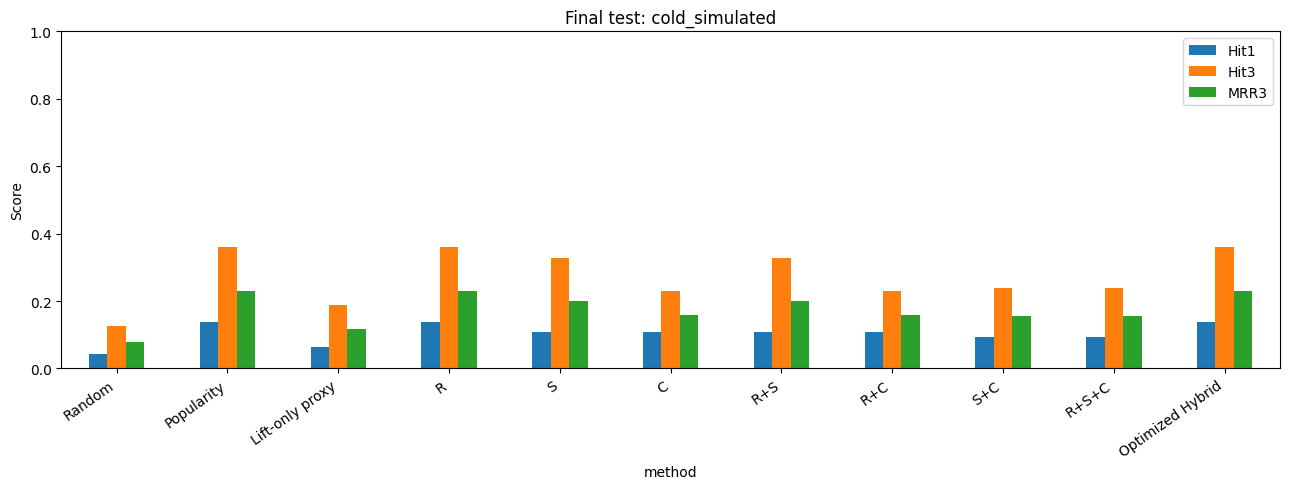

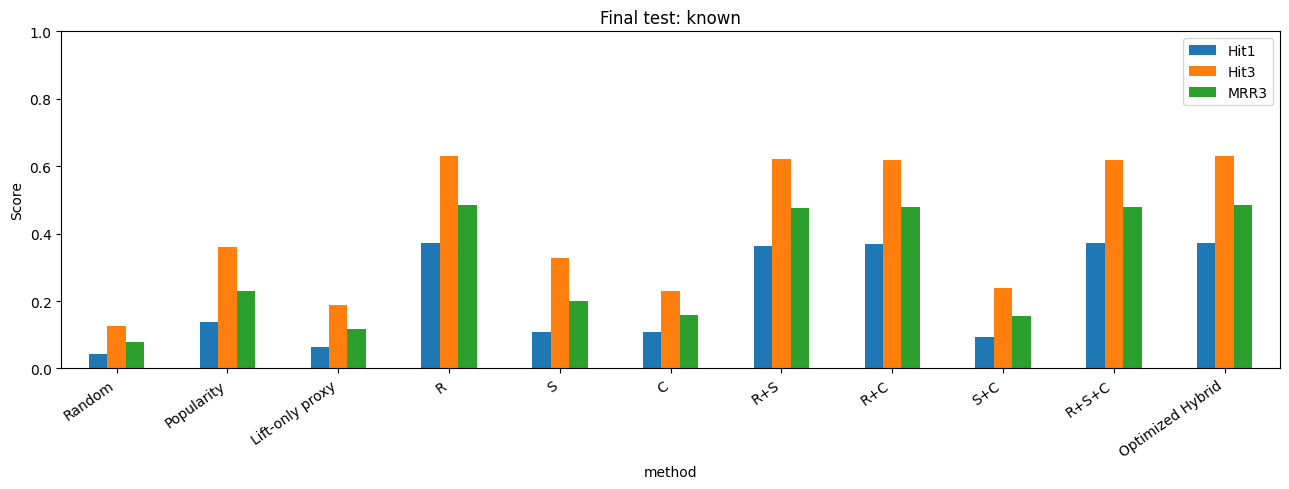

저장: /content/drive/MyDrive/2026_02_ROKEY/07_cobot2/recommender/evaluation_v3
['cold_simulated_metrics.png', 'evaluation_metadata.json', 'experiment_results.csv', 'hybrid_scores_optimized.json', 'hybrid_weights.json', 'known_metrics.png', 'segment_results.csv', 'weight_search_results.csv']


In [9]:
for scenario,g in res.groupby('scenario'):
    ax=g.set_index('method')[['Hit1','Hit3','MRR3']].plot.bar(figsize=(13,5),ylim=(0,1),title=f'Final test: {scenario}')
    ax.set_ylabel('Score'); plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.savefig(OUT/f'{scenario}_metrics.png',dpi=150); plt.show()
weights_payload={'R':best[0],'S':best[1],'C':best[2],'selection':'validation Hit@3 then MRR@3 then Hit@1','source':VERSION,'seed':SEED,'max_cases':MAX_CASES,'min_count':MIN_COUNT,'s_scope':S_SCOPE,'c_scope':C_SCOPE,'lift_weight':LIFT_WEIGHT}
(OUT/'hybrid_weights.json').write_text(json.dumps(weights_payload,indent=2))
(OUT/'evaluation_metadata.json').write_text(json.dumps({**coverage,'validation_cases':len(val),'test_cases':len(test),'seed':SEED,'max_cases':MAX_CASES,'mapping_review_file_used':meta['mapping_review_file_used'],'baseline':'reconstructed Lift-only proxy, not original web engine','inventory':'all available','cold_start':'history masked'},indent=2))
# Web export: do not export Instacart user IDs or purchase histories
payload={'schema_version':1,'source':VERSION,'item_ids':ids,'item_aisle':aisle,'names':names,'popularity':dict(zip(ids,map(float,pop))),'weights':dict(zip(['R','S','C'],best)),'min_count':MIN_COUNT,'s_scope':S_SCOPE,'c_scope':C_SCOPE,'lift_weight':LIFT_WEIGHT,'s_pairs':[{'source':str(a),'target':str(b),'score':v} for (a,b),v in s_pairs.items()],'c_pairs':[{'source':int(a),'target':int(b),'score':v} for (a,b),v in c_pairs.items()],'offline_evaluated':True,'validated':False,'max_cases':MAX_CASES}
(OUT/'hybrid_scores_optimized.json').write_text(json.dumps(payload,ensure_ascii=False,indent=2))
print('저장:',OUT); print(sorted(x.name for x in OUT.iterdir()))


## 해석 체크리스트
- R+C와 R+S+C 비교: S 추가 효과 (특히 S_available 부분).
- Lift-only proxy 대비 개선: 동일 후보의 통계 점수 비교. 실제 기존 웹 엔진과 직접 비교하려면 별도 공통 23종 평가가 필요하다.
- 신규 고객은 모의 평가이며 실제 신규 고객의 행동 분포와 다를 수 있다.
- C는 aisle 수준, S/R은 상품군 수준이다. 자동 매핑의 오류와 미국 식료품 구매 환경 차이를 고려한다.
- 최종 test로 가중치를 다시 선택하지 않는다. 실제 웹 적용 전 27종 카탈로그 및 실재고 연동 검증 필요.